# LAB ASSIGNMENT 1

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/datasets/CC_Customer_Dataset.csv')
df.info()

features = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank','Total_visits_online', 'Total_calls_made']
X = df[features].values
print(X.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB
(660, 5)


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

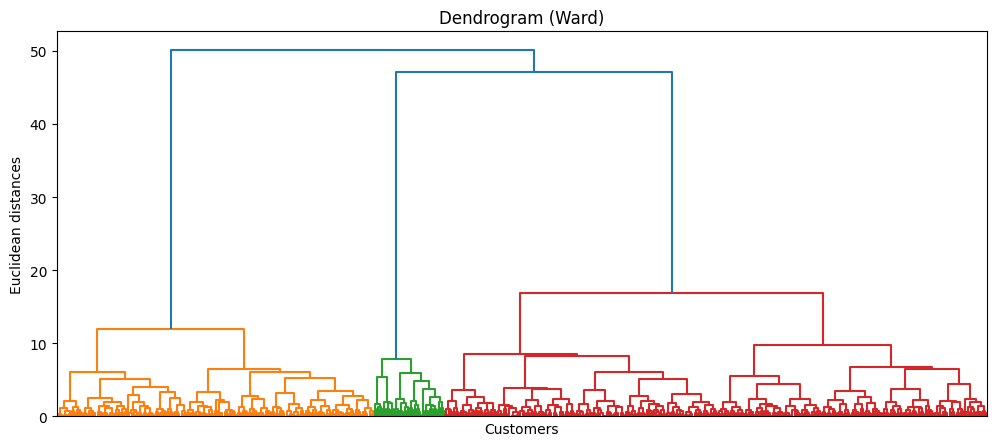

In [6]:
plt.figure(figsize=(12, 5))
sch.dendrogram(sch.linkage(X_scaled, method='ward'), no_labels=True)
plt.title('Dendrogram (Ward)')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.show()

In [7]:
for k in range(2, 9):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    print(k, round(silhouette_score(X_scaled, labels), 4))

2 0.4177
3 0.5148
4 0.3481
5 0.2569
6 0.2268
7 0.2163
8 0.2187


In [8]:
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X_scaled)
df['Cluster'] = y_hc
print(df['Cluster'].value_counts().sort_index())

Cluster
0    385
1    225
2     50
Name: count, dtype: int64


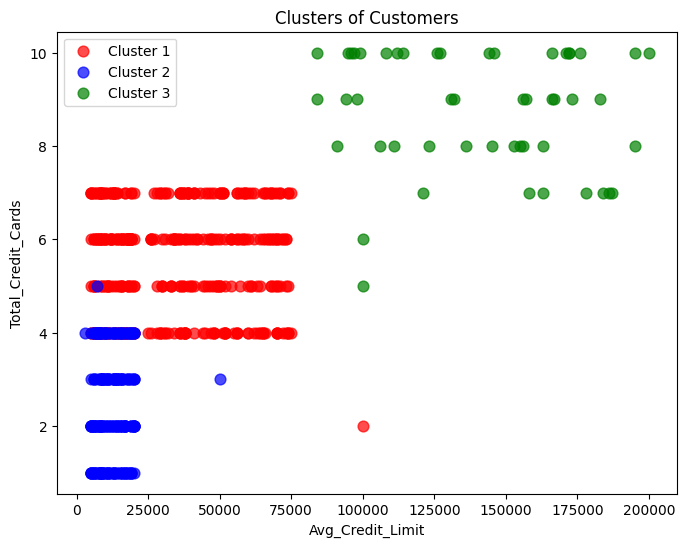

In [9]:
colors = ['red', 'blue', 'green']
plt.figure(figsize=(8, 6))
for i in range(3):
    plt.scatter(df.loc[y_hc == i, 'Avg_Credit_Limit'],
                df.loc[y_hc == i, 'Total_Credit_Cards'],
                s=60, c=colors[i], label=f'Cluster {i+1}', alpha=0.7)
plt.title('Clusters of Customers')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.legend()
plt.show()

In [10]:
sil = silhouette_score(X_scaled, y_hc)
dbi = davies_bouldin_score(X_scaled, y_hc)
print(f'Silhouette Score    : {sil:.4f}')
print(f'Davies-Bouldin Index: {dbi:.4f}')

Silhouette Score    : 0.5148
Davies-Bouldin Index: 0.6810


In [11]:
print(df.groupby('Cluster')[features].mean().round(2))

         Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
Cluster                                                            
0                33851.95                5.52               3.49   
1                12151.11                2.42               0.94   
2               141040.00                8.74               0.60   

         Total_visits_online  Total_calls_made  
Cluster                                         
0                       0.98              1.99  
1                       3.55              6.86  
2                      10.90              1.08  


# LAB ASSIGNMENT 2

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
iris = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/datasets/iris.csv')
X = iris.iloc[:, :4].values
y_true = iris['species']
print(iris.shape)
print(y_true.value_counts())

(150, 5)
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [14]:
hdb = HDBSCAN(min_cluster_size=5, copy=True)
labels = hdb.fit_predict(X)

In [15]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = (labels == -1).sum()
print(f'Jumlah cluster : {n_clusters}')
print(f'Jumlah noise   : {n_noise} ({n_noise/len(labels)*100:.1f}%)')

Jumlah cluster : 2
Jumlah noise   : 0 (0.0%)


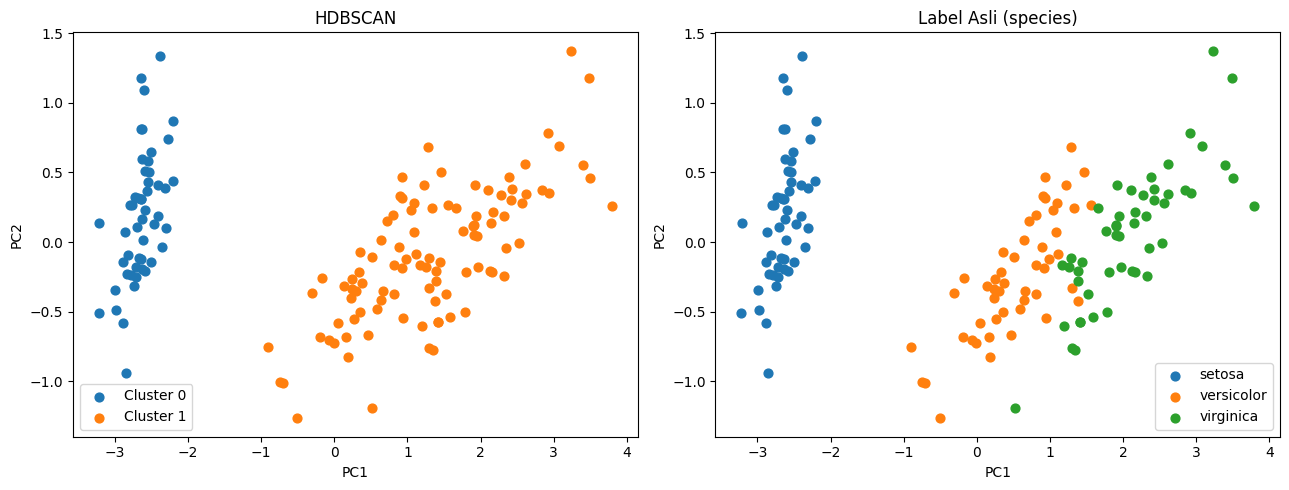

In [16]:
X_pca = PCA(n_components=2).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Hasil HDBSCAN
for k in sorted(set(labels)):
    m = labels == k
    axes[0].scatter(X_pca[m, 0], X_pca[m, 1], s=40,
                    c='black' if k == -1 else None,
                    marker='x' if k == -1 else 'o',
                    label='Noise' if k == -1 else f'Cluster {k}')
axes[0].set_title('HDBSCAN')
axes[0].legend()

# Label asli
for sp in y_true.unique():
    m = (y_true == sp).values
    axes[1].scatter(X_pca[m, 0], X_pca[m, 1], s=40, label=sp)
axes[1].set_title('Label Asli (species)')
axes[1].legend()

for ax in axes:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

In [17]:
print(pd.crosstab(y_true, labels, rownames=['species'], colnames=['HDBSCAN']))
print('Adjusted Rand Index:', round(adjusted_rand_score(y_true, labels), 4))

HDBSCAN      0   1
species           
setosa      50   0
versicolor   0  50
virginica    0  50
Adjusted Rand Index: 0.5681
